# Chapter 6 — Advanced Logistic Regression and Extensions
**Buku:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt, 2025)

**Ringkasan chapter.** Regresi logistik bukan hanya untuk klasifikasi biner. Chapter ini membahas dasar regresi logistik, perluasannya ke **multiclass** (One-vs-Rest dan multinomial/softmax), **regularisasi** (L1/L2 lewat parameter `C`), **multilabel** (satu sampel punya beberapa label sekaligus), dan **metrik evaluasi** (precision, recall, F1, ROC-AUC).

| # | Recipe | Dataset |
|---|---|---|
| 1 | Overview of logistic regression | Breast Cancer |
| 2 | Multiclass classification techniques | Iris |
| 3 | Regularization in logistic regression | Breast Cancer |
| 4 | Multilabel classification concepts | Sintetis (`make_multilabel_classification`) |
| 5 | Model evaluation metrics | Breast Cancer |

> Bagian *Hands-on exercises* dan *Practical exercises* tidak dimasukkan. Beberapa kode buku disesuaikan agar berjalan di scikit-learn terbaru; setiap penyesuaian dicatat di sel terkait.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import classification_report, accuracy_score

def show_report(y_true, y_pred, target_names=None, **kw):
    """Classification report -> DataFrame berwarna (menggantikan blok styling yang diulang di buku)."""
    rep = pd.DataFrame(classification_report(y_true, y_pred, target_names=target_names,
                                             output_dict=True, **kw)).transpose()
    return (rep.style
            .background_gradient(cmap="Blues", subset=["precision", "recall", "f1-score"])
            .format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:.0f}"}))

import seaborn as sns
import sklearn
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.8.0


## 1. Overview of Logistic Regression

### Konsep
- **Regresi logistik** memprediksi **probabilitas** sebuah sampel masuk ke kelas tertentu, lalu probabilitas itu diubah menjadi kelas lewat ambang (*threshold*, umumnya 0,5).
- Kombinasi linear fitur $z = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$ dimasukkan ke **fungsi sigmoid** sehingga hasilnya antara 0 dan 1:
$$P(Y=1 \mid X) = \frac{1}{1 + e^{-z}}$$
- **Log-odds** (logit): $\ln\frac{p}{1-p} = z$. Jadi model bersifat linear pada skala log-odds, dan batas keputusannya ($z=0$, yaitu $p=0{,}5$) berupa garis/bidang lurus pada ruang fitur. Koefisien $\beta_j$ dibaca sebagai perubahan log-odds per kenaikan satu unit fitur ($e^{\beta_j}$ = *odds ratio*).
- Parameter diestimasi dengan **Maximum Likelihood Estimation (MLE)**, yaitu meminimalkan *log-loss*: $-\sum [y\log p + (1-y)\log(1-p)]$.
- **Odds** = peluang kejadian dibanding peluang tidak terjadi, $\frac{p}{1-p}$.

> **Catatan koreksi:** rumus di buku tertulis `β_n + X_n` pada eksponen; yang benar adalah **perkalian** $\beta_n X_n$ seperti di atas.

### Kode

In [2]:
# [Buku] Getting ready: muat data dan split (80% latih, 20% uji)
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

data = load_breast_cancer()
X = data.data
y = data.target
df = pd.DataFrame(X, columns=data.feature_names)
df["target"] = y

X_train, X_test, y_train, y_test = train_test_split(
    df[data.feature_names], df["target"], test_size=0.2, random_state=2024)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (455, 30) | Test: (114, 30)


In [3]:
# [Buku] How to do it: latih, prediksi, evaluasi
model = LogisticRegression(max_iter=10000)   # naikkan max_iter bila ada masalah konvergensi
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")   # buku: 0.95

Accuracy: 0.95


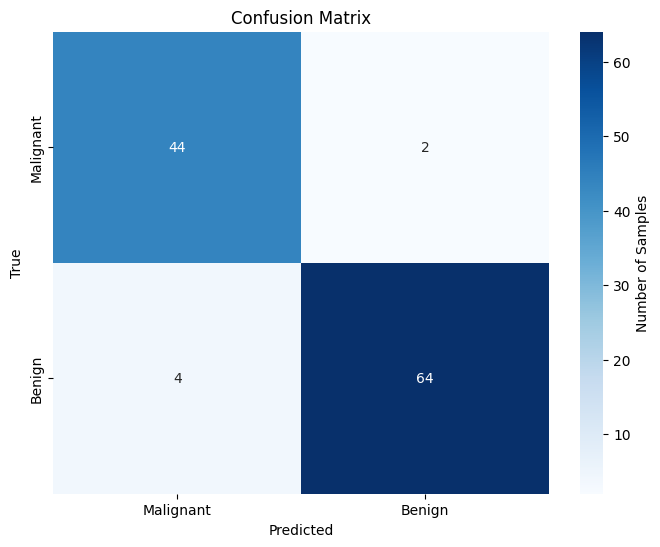

In [4]:
# [Buku] Confusion matrix (buku memakai plt dan sns tanpa mengimpornya di recipe ini)
class_names = ["Malignant", "Benign"]   # di dataset ini target 0 = malignant, 1 = benign
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={"label": "Number of Samples"})
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix")
plt.show()

In [5]:
# [Buku] Classification report
show_report(y_test, y_pred, target_names=class_names)

,precision,recall,f1-score,support
Malignant,0.917,0.957,0.936,46
Benign,0.970,0.941,0.955,68
accuracy,0.947,0.947,0.947,1
macro avg,0.943,0.949,0.946,114
weighted avg,0.948,0.947,0.948,114


### Hasil dan interpretasi
- Akurasi **0,947** (≈ 0,95 di buku). Confusion matrix (Figure 6.1): dari 46 kasus *Malignant*, 44 terdeteksi benar dan 2 salah diprediksi *Benign*; dari 68 kasus *Benign*, 64 benar dan 4 salah diprediksi *Malignant*.
- Report: recall *Malignant* **0,957**, recall *Benign* 0,941; precision *Malignant* 0,917, *Benign* 0,970. Macro avg dan weighted avg hampir sama karena kelasnya tidak terlalu timpang (46 vs 68). (Angka 1 pada kolom *support* di baris `accuracy` hanyalah artefak format `classification_report`.)
- **Pertanyaan buku: metrik apa yang lebih tepat daripada accuracy?** Pada deteksi kanker, kesalahan paling berbahaya adalah *false negative* (kasus ganas dinyatakan jinak), sehingga **recall kelas *Malignant*** (0,957; 2 dari 46 kasus ganas terlewat) lebih relevan daripada akurasi keseluruhan.

## 2. Multiclass Classification Techniques

### Konsep
Dua strategi memperluas regresi logistik ke lebih dari dua kelas:

| | **One-vs-Rest (OvR / OvA)** | **Multinomial (Softmax)** |
|---|---|---|
| Ide | Latih **satu classifier biner per kelas** (kelas itu = positif, semua kelas lain = negatif) | Latih **satu model** yang langsung memodelkan semua kelas |
| Prediksi | Kelas dengan skor/keyakinan tertinggi | Kelas dengan probabilitas softmax tertinggi |
| Probabilitas | Skor tiap classifier tidak otomatis berjumlah 1 | Berjumlah 1 (distribusi probabilitas atas kelas) |
| Cocok untuk | Kelas yang tidak saling eksklusif / kasus sederhana | Kelas yang **saling eksklusif** |

Fungsi **softmax**: $P(y=k \mid x) = \dfrac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$, dengan satu set koefisien per kelas yang dioptimasi bersamaan.

**Pertimbangan** (dari buku): pilih *solver* yang sesuai (`liblinear` klasik untuk OvR; `lbfgs`/`newton-cg` untuk multinomial), gunakan regularisasi, dan skalakan fitur numerik. **Macro avg** = rata-rata metrik antar kelas tanpa memperhatikan jumlah sampel; **weighted avg** = rata-rata berbobot jumlah sampel (*support*).

> **Penyesuaian versi:** di scikit-learn 1.7 ke atas parameter `multi_class` **dihapus**, dan `solver="liblinear"` **tidak lagi mendukung multiclass** (akan menghasilkan `ValueError`). Kode buku `LogisticRegression(solver="liblinear")` dan `LogisticRegression(multi_class="multinomial", ...)` karenanya diganti dengan padanannya: OvR memakai `OneVsRestClassifier(LogisticRegression(solver="liblinear"))`, sedangkan multinomial adalah perilaku **default** untuk $\ge 3$ kelas.

### Kode

In [6]:
# [Buku] Getting ready: Iris, split 70/30
from sklearn.datasets import load_iris
from sklearn.multiclass import OneVsRestClassifier

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df["target"] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (105, 4) | Test: (45, 4)


In [7]:
# [Buku, disesuaikan] OvR dan multinomial
ovr_model = OneVsRestClassifier(LogisticRegression(solver="liblinear"))
ovr_model.fit(X_train, y_train)

multinomial_model = LogisticRegression(solver="lbfgs", max_iter=1000)   # multinomial = default untuk >= 3 kelas
multinomial_model.fit(X_train, y_train)

y_pred_ovr = ovr_model.predict(X_test)
y_pred_multinomial = multinomial_model.predict(X_test)
print("Akurasi OvR        :", round(accuracy_score(y_test, y_pred_ovr), 3))
print("Akurasi multinomial:", round(accuracy_score(y_test, y_pred_multinomial), 3))

Akurasi OvR        : 0.956
Akurasi multinomial: 0.933


In [8]:
# [Buku] Classification report OvR
print("One-vs-Rest (OvR) Logistic Regression:")
show_report(y_test, y_pred_ovr)

One-vs-Rest (OvR) Logistic Regression:


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.917,0.917,0.917,12
2,0.933,0.933,0.933,15
accuracy,0.956,0.956,0.956,1
macro avg,0.950,0.950,0.950,45
weighted avg,0.956,0.956,0.956,45


In [9]:
# [Buku] Classification report multinomial
print("Multinomial Logistic Regression:")
show_report(y_test, y_pred_multinomial)

Multinomial Logistic Regression:


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.846,0.917,0.880,12
2,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


### Hasil dan interpretasi
- Akurasi **OvR 0,956** vs **multinomial 0,933** (sama dengan Figure 6.3 dan 6.4). Selisihnya hanya **satu sampel uji** dari 45 (43 vs 42 benar), jadi tidak cukup untuk menyimpulkan OvR lebih baik.
- Kelas 0 (*Setosa*) sempurna pada kedua model; kesalahan terjadi antara kelas 1 (*Versicolor*) dan 2 (*Virginica*), yang memang tumpang tindih (lihat pairplot di bawah).
- Macro avg ≈ weighted avg karena *support* antar kelas cukup seimbang (18/12/15); keduanya akan berbeda jauh pada data yang timpang.
- **Koreksi teks buku:** (1) kalimat sebelum Figure 6.3 menyebut *confusion matrix*, padahal yang ditampilkan *classification report*; (2) paragraf setelah Figure 6.4 menyebut multinomial dipakai "untuk masalah klasifikasi biner", padahal Iris punya **3 kelas**.

### There's more…: pairplot
`seaborn.pairplot` membantu melihat seberapa baik fitur memisahkan kelas.

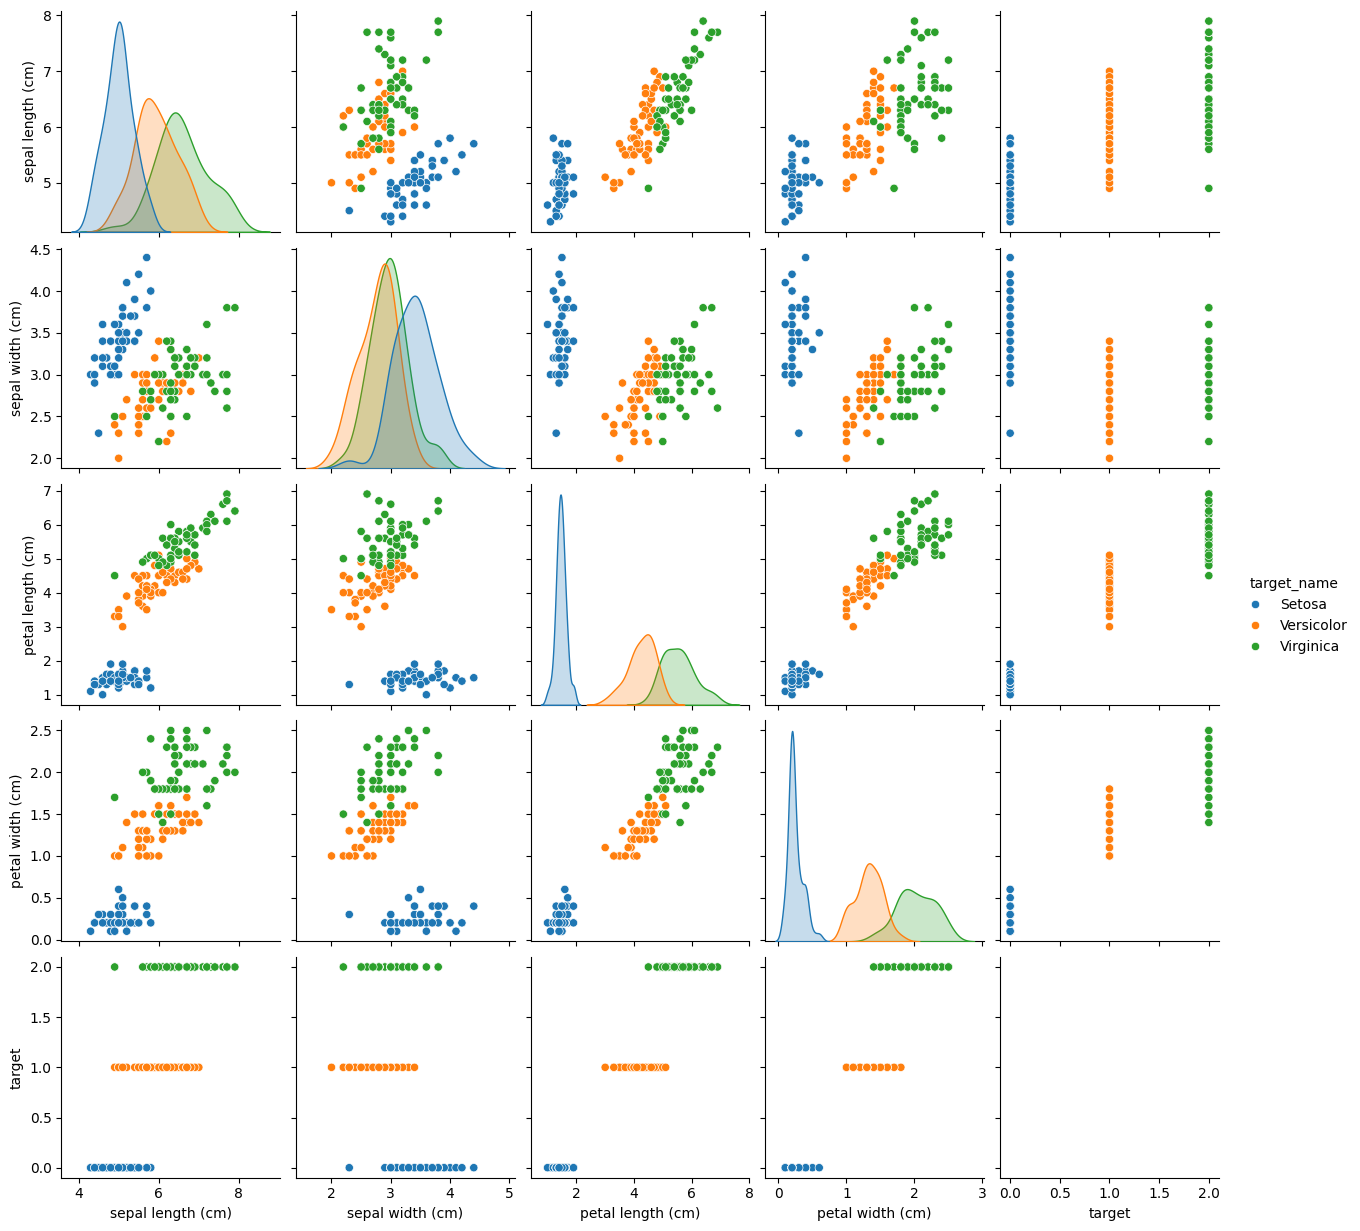

In [10]:
# [Buku] Pairplot Iris
target_names = {0: "Setosa", 1: "Versicolor", 2: "Virginica"}
df["target_name"] = df["target"].map(target_names)
sns.pairplot(df, hue="target_name", diag_kind="kde")
plt.show()

**Interpretasi:** *Setosa* (biru) terpisah jelas dari dua kelas lain pada hampir semua pasangan fitur, terutama `petal length` dan `petal width`. *Versicolor* dan *Virginica* saling tumpang tindih sebagian, dan di situlah kesalahan klasifikasi terjadi. Distribusi `petal length` dan `petal width` sempit dan terpisah antar kelas, sehingga fitur-fitur itu paling informatif. (Catatan: karena `df` masih berisi kolom numerik `target`, pairplot ikut menggambar kolom itu sebagai fitur; buku tidak membuangnya.)

## 3. Regularization in Logistic Regression

### Konsep
- **Regularisasi** menambahkan **penalti** pada fungsi loss agar koefisien tidak terlalu besar, sehingga mengurangi *overfitting* dan memperbaiki generalisasi (mengatur *bias-variance trade-off*).
- **L2 / Ridge:** penalti proporsional dengan **kuadrat** koefisien. Koefisien mengecil mendekati 0 tetapi jarang tepat 0, jadi semua fitur tetap dipakai.
- **L1 / Lasso:** penalti proporsional dengan **nilai absolut** koefisien. Dapat membuat sebagian koefisien **tepat 0**, yaitu model *sparse* dengan seleksi fitur otomatis.
- Parameter **`C`** = **kebalikan** kekuatan regularisasi ($C = 1/\lambda$): **`C` kecil → regularisasi kuat**. Fungsi objektif scikit-learn: $\min_w\ \tfrac{1}{2}\lVert w\rVert_2^2 + C\sum_i \text{logloss}_i$ (L2), atau $\lVert w\rVert_1 + C\sum_i \text{logloss}_i$ (L1).
- **Pertimbangan:** `liblinear` mendukung L1 dan L2 untuk data kecil; `saga` untuk data besar. **Skalakan data** karena penalti sensitif terhadap skala fitur. Tuning `C` dengan grid/random search + cross-validation.

> **Catatan versi:** di scikit-learn 1.8 parameter `penalty` dinyatakan *deprecated* (akan dihapus di 1.10), tetapi masih berfungsi dan hanya menampilkan peringatan (disembunyikan di notebook ini). Dipertahankan agar sama dengan buku.

### Kode

In [11]:
# [Buku] Getting ready: Breast Cancer, split 70/30, lalu scaling
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit hanya pada data latih
X_test = scaler.transform(X_test)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (398, 30) | Test: (171, 30)


In [12]:
# [Buku] Ridge (L2) dan Lasso (L1), C = 0.1
ridge_model = LogisticRegression(penalty="l2", solver="liblinear", C=0.1)
ridge_model.fit(X_train, y_train)

lasso_model = LogisticRegression(penalty="l1", solver="liblinear", C=0.1)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)
print("Akurasi Ridge:", round(accuracy_score(y_test, y_pred_ridge), 3))
print("Akurasi Lasso:", round(accuracy_score(y_test, y_pred_lasso), 3))
print("Koefisien bernilai 0 (dari 30) -> Ridge:", int((ridge_model.coef_ == 0).sum()),
      "| Lasso:", int((lasso_model.coef_ == 0).sum()))

Akurasi Ridge: 0.982
Akurasi Lasso: 0.965
Koefisien bernilai 0 (dari 30) -> Ridge: 0 | Lasso: 23


In [13]:
# [Buku] Classification report Ridge
print("Ridge (L2) Regularized Logistic Regression:")
show_report(y_test, y_pred_ridge)

Ridge (L2) Regularized Logistic Regression:


,precision,recall,f1-score,support
0,0.985,0.970,0.977,67
1,0.981,0.990,0.986,104
accuracy,0.982,0.982,0.982,1
macro avg,0.983,0.980,0.982,171
weighted avg,0.982,0.982,0.982,171


In [14]:
# [Buku] Classification report Lasso
print("Lasso (L1) Regularized Logistic Regression:")
show_report(y_test, y_pred_lasso)

Lasso (L1) Regularized Logistic Regression:


,precision,recall,f1-score,support
0,0.930,0.985,0.957,67
1,0.990,0.952,0.971,104
accuracy,0.965,0.965,0.965,1
macro avg,0.960,0.968,0.964,171
weighted avg,0.966,0.965,0.965,171


### Hasil dan interpretasi
- Akurasi **Ridge 0,982** vs **Lasso 0,965** (sama dengan Figure 6.6 dan 6.7). Pada `C=0,1`, Ridge mempertahankan **semua 30** koefisien (tidak ada yang nol), sedangkan Lasso menolkan **23 koefisien** sehingga hanya 7 fitur yang dipakai. Model Lasso jauh lebih sederhana, dengan akurasi hanya turun 1,7 poin.
- Klaim buku "Ridge unggul di precision dan Lasso unggul di recall" **hanya benar untuk kelas 0** (*malignant*): precision 0,985 (Ridge) vs 0,930 (Lasso), recall 0,970 vs 0,985. Untuk kelas 1 justru sebaliknya: precision 0,981 (Ridge) vs 0,990 (Lasso), recall 0,990 vs 0,952. Jadi kesimpulan perlu disebut per kelas dan sesuai metrik yang dipilih, serta selisihnya kecil pada 171 sampel uji.
- Fitur diskalakan dengan `StandardScaler` yang di-`fit` hanya pada data latih.

### There's more…: koefisien vs kekuatan regularisasi

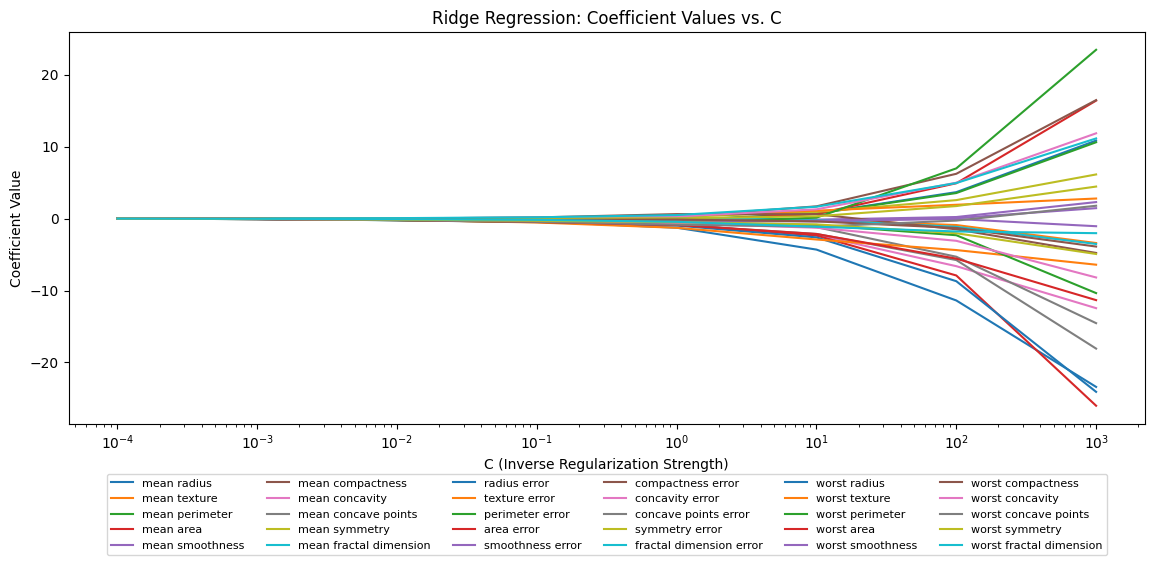

In [15]:
# [Buku] Koefisien vs C (Ridge)
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_ridge = []
for C in C_values:
    m = LogisticRegression(penalty="l2", solver="liblinear", C=C)
    m.fit(X_train, y_train)
    coefs_ridge.append(m.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_ridge], label=feature_names[i])
plt.xscale("log")
plt.xlabel("C (Inverse Regularization Strength)"); plt.ylabel("Coefficient Value")
plt.title("Ridge Regression: Coefficient Values vs. C")
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc="lower center", fontsize=8)
plt.tight_layout(); plt.show()

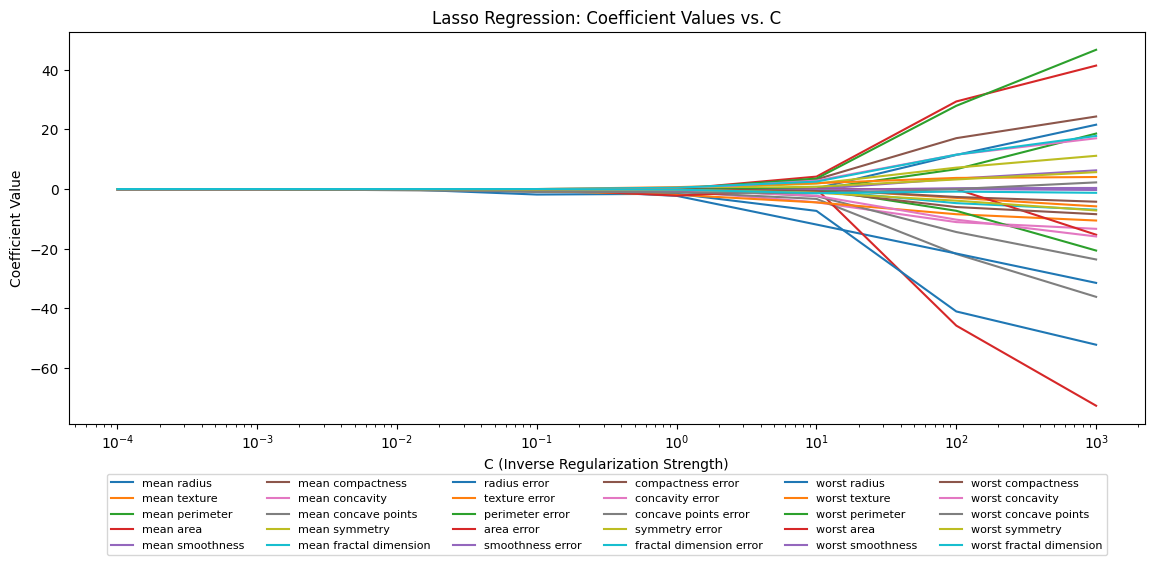

In [16]:
# [Buku] Koefisien vs C (Lasso)
coefs_lasso = []
for C in C_values:
    m = LogisticRegression(penalty="l1", solver="liblinear", C=C)
    m.fit(X_train, y_train)
    coefs_lasso.append(m.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_lasso], label=feature_names[i])
plt.xscale("log")
plt.xlabel("C (Inverse Regularization Strength)"); plt.ylabel("Coefficient Value")
plt.title("Lasso Regression: Coefficient Values vs. C")
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc="lower center", fontsize=8)
plt.tight_layout(); plt.show()

**Cara membaca:** sumbu-x adalah `C` (skala log); semakin ke **kiri** (C kecil) regularisasi semakin kuat sehingga semua koefisien mendekati 0, dan semakin ke **kanan** koefisien makin bebas membesar. Pada Lasso, sebagian garis menempel tepat di 0 untuk rentang `C` tertentu (fitur "dibuang"); pada Ridge garis hanya mengecil mulus.

## 4. Multilabel Classification Concepts

### Konsep
- **Multiclass:** tiap sampel punya **tepat satu** kelas dari beberapa kelas. **Multilabel:** tiap sampel dapat memiliki **beberapa label sekaligus** (contoh: kategori teks, tag gambar, fungsi gen).
- Target berupa **matriks indikator** $n \times K$ berisi 0/1 (satu kolom per label).
- **Binary relevance (OvR per label):** latih satu classifier biner untuk tiap label secara independen. Sederhana, tetapi mengabaikan hubungan antar label. Alternatif: **classifier chains** (label sebelumnya dipakai sebagai fitur) dan *label powerset*.
- `MultiOutputClassifier(estimator)` adalah jalan pintas yang menerapkan satu estimator ke tiap kolom target.
- Metrik pada multilabel: **subset accuracy** (`accuracy_score`; sampel dianggap benar hanya bila **semua** labelnya benar, sangat ketat), serta rata-rata precision/recall/F1: **micro** (menggabungkan semua keputusan), **macro** (rata-rata antar label, bobot sama), **weighted** (berbobot support), dan **samples** (dihitung per sampel lalu dirata-rata).
- Argumen `n_labels=2` pada `make_multilabel_classification` hanyalah **rata-rata** label per sampel, bukan jaminan (sampel bisa punya 0, 1, 2, 3, … label).

### Kode

In [17]:
# [Buku] Getting ready: dataset multilabel sintetis
from sklearn.datasets import make_multilabel_classification

X, y = make_multilabel_classification(
    n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024)
df = pd.DataFrame(X, columns=[f"feature_{i}" for i in range(X.shape[1])])
df["target"] = list(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print("X:", X.shape, "| y:", y.shape, "(matriks indikator 1000 x 5)")

X: (1000, 20) | y: (1000, 5) (matriks indikator 1000 x 5)


In [18]:
# [Buku] Satu model per label (OvR / binary relevance)
models = []
y_pred_all = []
for i in range(y_train.shape[1]):
    model = LogisticRegression(solver="liblinear")
    model.fit(X_train, y_train[:, i])
    models.append(model)
    y_pred_all.append(model.predict(X_test))

y_pred = np.array(y_pred_all).T     # transpos agar bentuknya sama dengan y_test
print("Subset accuracy (exact match):", round(accuracy_score(y_test, y_pred), 3))

Subset accuracy (exact match): 0.34


In [19]:
# [Buku] Classification report multilabel
print("Classification Report:")
show_report(y_test, y_pred, zero_division=1)

Classification Report:


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562


In [20]:
# [Buku, kotak MultiOutputClassifier] Hasil yang sama dengan satu baris
from sklearn.multioutput import MultiOutputClassifier

moc = MultiOutputClassifier(LogisticRegression(solver="liblinear")).fit(X_train, y_train)
print("Prediksi identik dengan loop manual:", np.array_equal(moc.predict(X_test), y_pred))

Prediksi identik dengan loop manual: True


### Hasil dan interpretasi
- **Subset accuracy 0,34**: hanya sekitar sepertiga sampel uji yang kelima labelnya benar semua. Metrik ini sangat ketat sehingga tampak rendah walau sebagian label diprediksi cukup baik.
- Report sama dengan Figure 6.10. Label 0 dan 1 (frekuensi 55% dan 60%) diprediksi baik (F1 0,811 dan 0,823). Label 2, 3, dan 4 jauh lebih sulit, dengan recall hanya 0,333 / 0,176 / 0,477. Label 3 (hanya 11,3% sampel) paling buruk: 82% kemunculannya terlewat, hal yang umum terjadi pada label yang jarang.
- Rata-rata: **micro avg** (F1 0,701) menimbang tiap keputusan label sama sehingga didominasi label yang sering; **macro avg** (F1 0,577) menimbang tiap label sama sehingga turun akibat label langka; **samples avg** dihitung per sampel.
- `MultiOutputClassifier` menghasilkan prediksi **identik** dengan loop manual.

### Visualizing results: label co-occurrence
Matriks *co-occurrence* (mirip confusion matrix) menunjukkan label mana yang sering muncul bersamaan.

> **Perbaikan kode:** di buku, pemanggilan `sns.heatmap(... annot_kws={"fontsize": 15} vmin=0, vmax=1)` kehilangan tanda koma setelah `annot_kws` sehingga menjadi *SyntaxError*. Sudah diperbaiki di bawah.

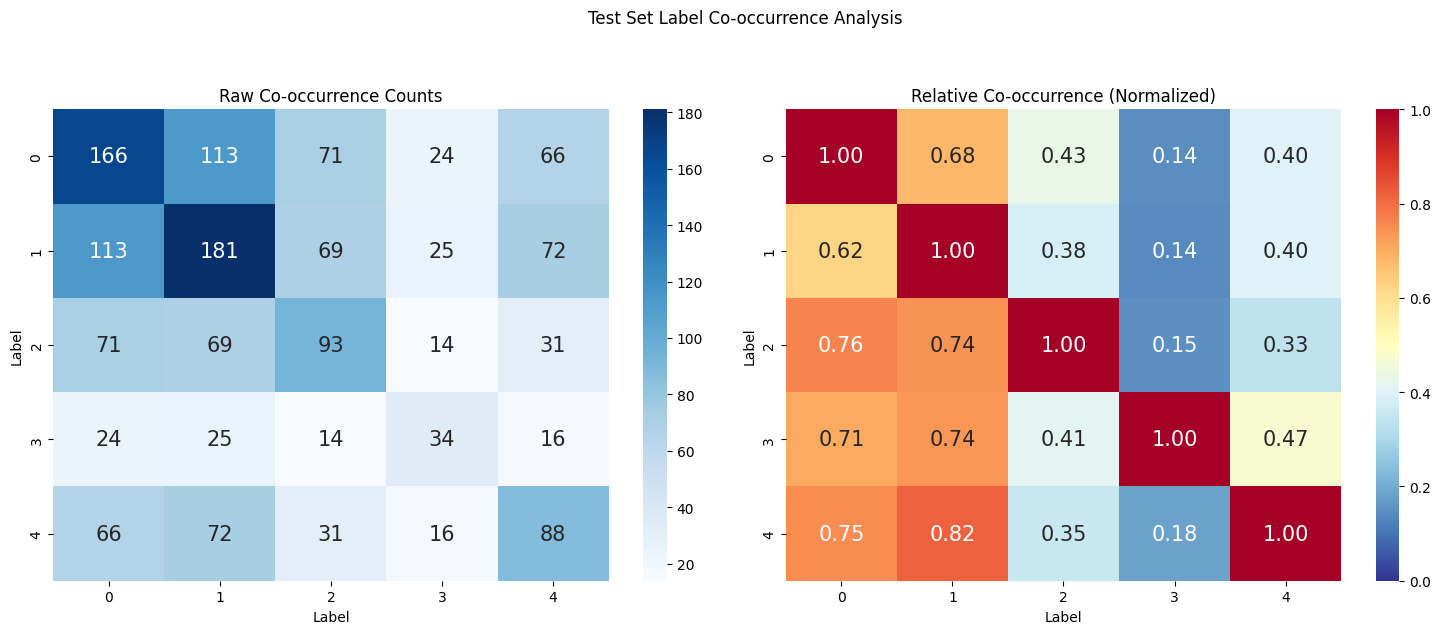


Label Statistics:
Total samples: 300

Label frequencies:
Label 0: 166 samples (55.3%)
Label 1: 181 samples (60.3%)
Label 2: 93 samples (31.0%)
Label 3: 34 samples (11.3%)
Label 4: 88 samples (29.3%)

Most common label combinations:
Combination [0 0 0 0 0]: 52 samples (17.3%)
Combination [0 1 0 0 0]: 34 samples (11.3%)
Combination [1 1 0 0 0]: 28 samples (9.3%)
Combination [1 1 1 0 0]: 25 samples (8.3%)
Combination [1 1 0 0 1]: 24 samples (8.0%)


In [21]:
# [Buku, diperbaiki] Fungsi co-occurrence
def plot_label_cooccurrence(y, title="Label Co-occurrence Analysis"):
    # I. Hitungan co-occurrence mentah
    cooccurrence = y.T @ y
    # II. Co-occurrence relatif (dinormalisasi dengan diagonal)
    diag = np.diag(cooccurrence)
    relative_cooccurrence = cooccurrence / diag[:, None]

    # III-V. Dua heatmap
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(cooccurrence, annot=True, fmt="d", cmap="Blues", ax=ax1, annot_kws={"fontsize": 15})
    ax1.set_title("Raw Co-occurrence Counts"); ax1.set_xlabel("Label"); ax1.set_ylabel("Label")
    sns.heatmap(relative_cooccurrence, annot=True, fmt=".2f", cmap="RdYlBu_r", ax=ax2,
                annot_kws={"fontsize": 15}, vmin=0, vmax=1)
    ax2.set_title("Relative Co-occurrence (Normalized)"); ax2.set_xlabel("Label"); ax2.set_ylabel("Label")
    plt.suptitle(title, y=1.05); plt.tight_layout(); plt.show()

    # VI. Statistik tambahan
    print("\nLabel Statistics:")
    print(f"Total samples: {len(y)}")
    print("\nLabel frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        print(f"Label {i}: {count} samples ({count / len(y) * 100:.1f}%)")
    print("\nMost common label combinations:")
    # VII. Kombinasi unik dan jumlahnya
    unique_combinations = np.unique(y, axis=0, return_counts=True)
    sorted_idx = np.argsort(-unique_combinations[1])
    for combo, count in zip(unique_combinations[0][sorted_idx][:5], unique_combinations[1][sorted_idx][:5]):
        print(f"Combination {combo}: {count} samples ({count / len(y) * 100:.1f}%)")

plot_label_cooccurrence(y_test, "Test Set Label Co-occurrence Analysis")

**Cara membaca matriks:** *kiri* = jumlah sampel yang memiliki label $i$ dan $j$ sekaligus (diagonal = total kemunculan label itu). *Kanan* = tiap **baris** dibagi diagonalnya, sehingga sel $(i, j)$ = proporsi sampel berlabel $i$ yang juga berlabel $j$, yaitu $P(\text{label } j \mid \text{label } i)$. Nilai mendekati 1 berarti label $j$ hampir selalu menyertai label $i$; mendekati 0 berarti jarang bersamaan. Matriks relatif **tidak simetris**, dan asimetri itu menunjukkan ketergantungan satu arah antar label. (Teks buku menyebut pembacaan ini dengan dua versi yang saling bertukar; yang konsisten dengan kodenya adalah $P(j \mid i)$ per baris.)

**Pada data ini:** label 0 dan 1 paling sering muncul bersamaan (113 sampel): $P(1\mid 0)=0{,}68$ dan $P(0\mid 1)=0{,}62$. Label 3 jarang menyertai label lain (misalnya $P(3\mid 0)=0{,}14$). Kombinasi paling umum adalah **tanpa label sama sekali** `[0 0 0 0 0]` (17,3%), yang membuktikan bahwa `n_labels=2` bukan jaminan jumlah label per sampel.

Alternatif lain selain binary relevance, seperti *classifier chains*, dapat menangkap ketergantungan antar label tersebut.

## 5. Model Evaluation Metrics

### Konsep
| Metrik | Arti | Rumus |
|---|---|---|
| **Accuracy** | Proporsi prediksi yang benar | $\frac{TP+TN}{TP+TN+FP+FN}$ |
| **Precision** | Dari yang diprediksi positif, berapa yang benar | $\frac{TP}{TP+FP}$ |
| **Recall** (sensitivity, TPR) | Dari semua positif sebenarnya, berapa yang tertangkap | $\frac{TP}{TP+FN}$ |
| **F1-score** | Rata-rata harmonik precision dan recall | $\frac{2PR}{P+R}$ |
| **ROC curve** | TPR vs FPR pada berbagai ambang (*threshold*); $FPR=\frac{FP}{FP+TN}$ | (kurva) |
| **AUC** | Luas di bawah kurva ROC; 0,5 = menebak acak, 1 = sempurna. Dapat dibaca sebagai peluang sampel positif acak diberi skor lebih tinggi daripada sampel negatif acak | (luas) |

**Memilih metrik:** bila *false positive* mahal, utamakan **precision**; bila penting menangkap sebanyak mungkin kasus positif (*false negative* mahal), utamakan **recall**. ROC/AUC menilai kemampuan membedakan kelas pada **semua** ambang sekaligus.

### Kode

In [22]:
# [Buku] Getting ready: Breast Cancer, split 70/30 (tanpa scaling)
from sklearn.metrics import precision_score, recall_score, f1_score, roc_curve, auc

data = load_breast_cancer()
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (398, 30) | Test: (171, 30)


In [23]:
# [Buku] Latih, prediksi (kelas dan probabilitas), hitung metrik
model = LogisticRegression(solver="liblinear")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]      # probabilitas kelas positif (1 = benign)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

print(f"Accuracy {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall {recall:.2f}")
print(f"F1 Score {f1:.2f}")
print(f"ROC AUC {roc_auc:.2f}")

Accuracy 0.94
Precision 0.94
Recall 0.95
F1 Score 0.95
ROC AUC 0.99


In [24]:
# [Buku] Classification report
show_report(y_test, y_pred)

,precision,recall,f1-score,support
0,0.924,0.910,0.917,67
1,0.943,0.952,0.947,104
accuracy,0.936,0.936,0.936,1
macro avg,0.934,0.931,0.932,171
weighted avg,0.936,0.936,0.936,171


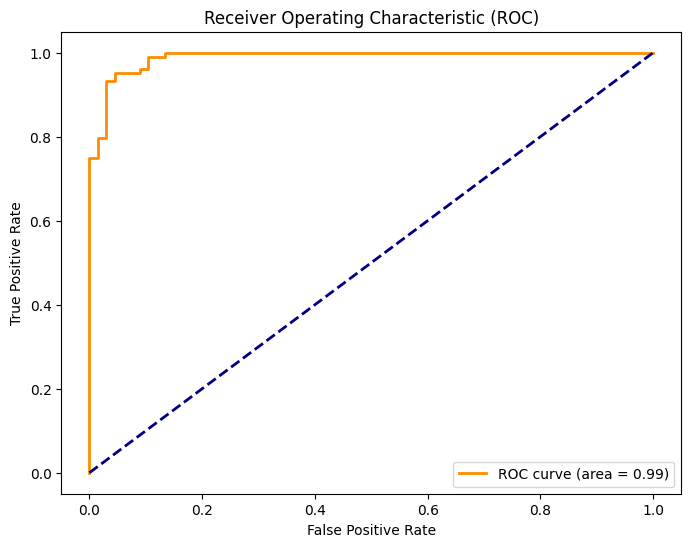

In [25]:
# [Buku] Kurva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()

### Hasil dan interpretasi
- Accuracy **0,94**, precision **0,94**, recall **0,95**, F1 **0,95**, ROC AUC **0,99** (persis seperti buku). Precision, recall, dan F1 pada cetakan atas dihitung untuk kelas positif = **1 (benign)**; untuk kelas *malignant* (0) precision 0,924 dan recall 0,910.
- **AUC 0,99** berarti model hampir selalu memberi skor lebih tinggi kepada sampel benign dibanding malignant; kurva ROC menempel di sudut kiri atas (TPR tinggi pada FPR rendah).
- Untuk kasus medis, recall kelas *malignant* (0,910) lebih penting. Ambang 0,5 dapat diturunkan untuk menaikkan recall dengan mengorbankan precision, dan kurva ROC menggambarkan pertukaran (*trade-off*) tersebut.

## Kesimpulan Chapter 6
- Regresi logistik memodelkan **log-odds sebagai fungsi linear fitur**, lalu sigmoid mengubahnya menjadi probabilitas; estimasi lewat MLE.
- **Multiclass:** OvR (satu model biner per kelas) vs **multinomial/softmax** (satu model gabungan, probabilitas berjumlah 1). Di scikit-learn terbaru multinomial adalah default, dan OvR dilakukan lewat `OneVsRestClassifier`.
- **Regularisasi:** `C` kecil = penalti kuat. **L2** menyusutkan koefisien, **L1** dapat menolkan koefisien (seleksi fitur). Selalu skalakan fitur.
- **Multilabel:** target berupa matriks indikator; binary relevance melatih satu classifier per label; evaluasi memakai micro/macro/weighted/samples average dan *subset accuracy* yang ketat.
- **Evaluasi:** pilih metrik sesuai biaya kesalahan (precision vs recall); ROC-AUC menilai pemisahan kelas pada semua ambang.